# Lab 3: Value Function Iteration

Open this working folder in **VS Code**, install `requirements.txt`, and select the `.venv` notebook kernel. Follow [README.md](README.md) for setup.

The `.py` files define the environments and computations. This notebook imports them, chooses parameters, and displays results. After editing a script, save it, restart the kernel, and run all cells again.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from maze import Maze
from mccall import McCallModel
from saving import ConsumptionSavingModel
from vfi import value_iteration, simulate_policy
from figures import (plot_maze, plot_convergence, plot_mccall,
                     plot_saving, plot_saving_rollout)

np.set_printoptions(precision=4, suppress=True)

## One algorithm, three environments

Each model supplies `initial_values()` and `bellman(v)`. The second method returns $Tv$ and a policy greedy with respect to $v$:

$$Q_k(s,a)=r(s,a)+\beta\mathbb{E}[v_k(s')\mid s,a],\qquad v_{k+1}(s)=\max_a Q_k(s,a).$$

Open `vfi.py` beside the notebook. Its loop updates values until the Bellman residual is small; `result["values"]` and `result["policy"]` retrieve entries from the returned dictionary.

## 1. Maze

Use the lecture maze with $\beta=0.9$. Moving costs $1$, including entry into the goal; subsequent rewards are zero. Cell 16 is the start and cell 8 is the goal. Python index $i$ corresponds to lecture cell $i+1$.

Value at start: -7.7123207545039
Path (lecture cell numbers): [16, 23, 31, 32, 33, 34, 25, 26, 27, 28, 29, 30, 22, 15, 8]


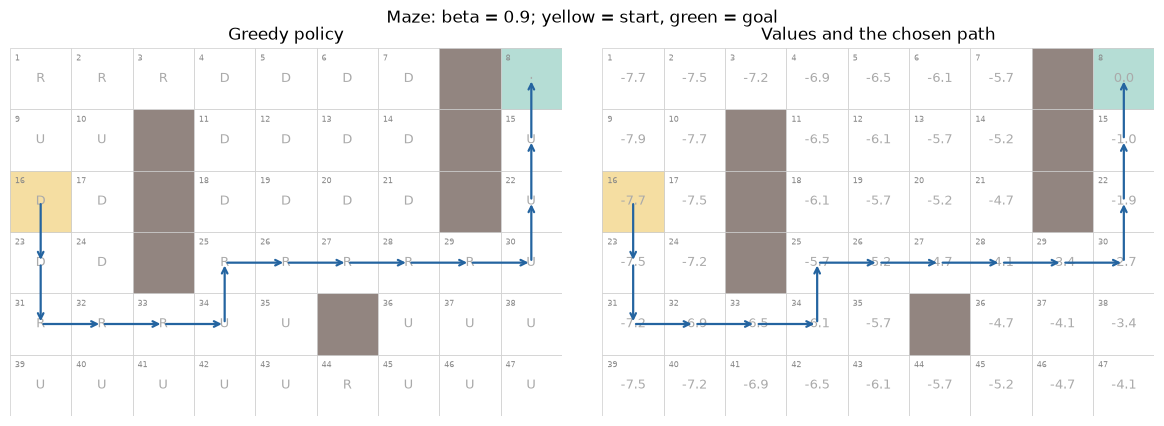

In [2]:
maze = Maze(beta=0.9)
maze_result = value_iteration(maze)
print("Value at start:", maze_result["values"][maze.start])
print("Path (lecture cell numbers):", [int(s) + 1 for s in maze.path(maze_result["policy"])])
plot_maze(maze, maze_result)
plt.show()

### Watch values propagate

The final corridor is 30 → 22 → 15 → 8. `history[k]` stores the value vector after $k$ updates.

Columns: cells 30, 22, 15, 8
v_0: [0. 0. 0. 0.]
v_1: [-1. -1. -1.  0.]
v_2: [-1.9 -1.9 -1.   0. ]
v_3: [-2.71 -1.9  -1.    0.  ]


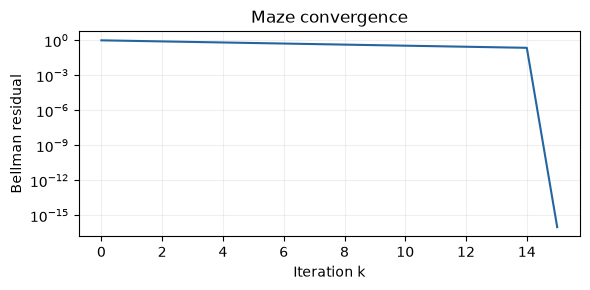

In [3]:
corridor = np.array([30, 22, 15, 8]) - 1
print("Columns: cells 30, 22, 15, 8")
for k in range(4):
    print(f"v_{k}:", maze_result["history"][k, corridor])
plot_convergence(maze_result, "Maze convergence")
plt.show()

## 2. McCall job search

As in Lab 2, the full state is $(U,w)$ or $(E,w)$. Accepting earns $w$ forever; rejecting earns $b$ and draws a new offer with probabilities $q$.

$$v_{k+1}((U,w))=\max\left\{\frac{w}{1-\beta},\ b+\beta\sum_{w'}q(w')v_k((U,w'))\right\}.$$

Start unemployed-state values at zero and keep the known employed-state values $v_k((E,w))=w/(1-\beta)$. `mccall.py` uses the same reward and transition methods as Lab 2.

('U', 1.0) value: 34.3243 action: reject
('U', 2.0) value: 34.3243 action: reject
('U', 3.0) value: 34.3243 action: reject
('U', 4.0) value: 40.0 action: accept
('U', 5.0) value: 50.0 action: accept


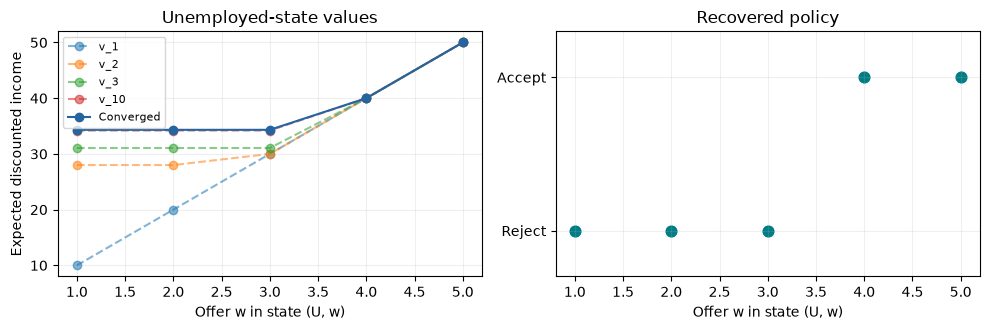

In [4]:
search = McCallModel(benefit=1.0, beta=0.9)
search_result = value_iteration(search)
for i in range(search.n):
    print(search.states[i], "value:", round(search_result["values"][i], 4),
          "action:", search_result["policy"][i])
plot_mccall(search, search_result)
plt.show()

v_0((U,w)): [0. 0. 0. 0. 0.]
v_1((U,w)): [10. 20. 30. 40. 50.]
v_2((U,w)): [28. 28. 30. 40. 50.]
v_3((U,w)): [31.06 31.06 31.06 40.   50.  ]
v_10((U,w)): [34.1957 34.1957 34.1957 40.     50.    ]


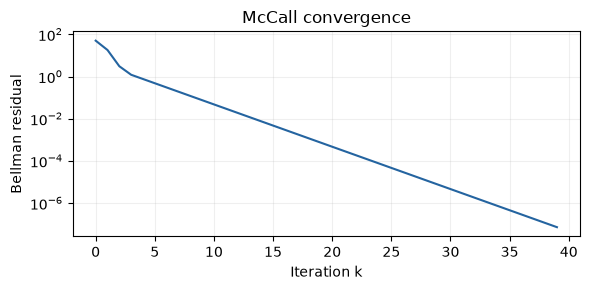

In [5]:
# Reproduce the first updates; [:search.n] selects unemployed states.
for k in [0, 1, 2, 3, 10]:
    print(f"v_{k}((U,w)):", search_result["history"][k, :search.n])
plot_convergence(search_result, "McCall convergence")
plt.show()

### Change a parameter

Raise the benefit and solve again. The environment changes; the VFI function stays the same.

In [6]:
higher_benefit = McCallModel(benefit=4.0, beta=0.9)
higher_result = value_iteration(higher_benefit)
for i in range(search.n):
    print(search.states[i], "b=1:", search_result["policy"][i],
          "b=4:", higher_result["policy"][i])

('U', 1.0) b=1: reject b=4: reject
('U', 2.0) b=1: reject b=4: reject
('U', 3.0) b=1: reject b=4: reject
('U', 4.0) b=1: accept b=4: reject
('U', 5.0) b=1: accept b=4: accept


### Simulate the recovered policy

A policy function selects an action from the current state, just as in Lab 2.

In [7]:
def search_policy(state):
    return search_result["policy"][state]

path, rewards = simulate_policy(search, search_policy, initial_state=1, periods=12)
print("States:", [search.states[i] for i in path])
print("Rewards:", rewards)

States: [('U', 2.0), ('U', 3.0), ('U', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0), ('E', 4.0)]
Rewards: [1. 1. 4. 4. 4. 4. 4. 4. 4. 4. 4. 4.]


## 3. Continuous consumption-saving

Stock is $s\in[0,M+B]$. Save $a\in[0,\min(s,M)]$, consume $s-a$, and draw $Y'\sim\mathrm{Uniform}[0,B]$. Next stock is $s'=a+Y'$; reward is $(s-a)^\alpha$.

$$v_{k+1}(s)=\max_{0\leq a\leq\min(s,M)}\left\{(s-a)^\alpha+\frac{\beta}{B}\int_0^Bv_k(a+y)\,dy\right\}.$$

In `saving.py`, linear interpolation supplies values between stock points, midpoint integration approximates the income average, and an action grid approximates maximization. The model's states and actions remain continuous.

Completed updates: 133
Numerical-operator error bound: 9.66462458507067e-06


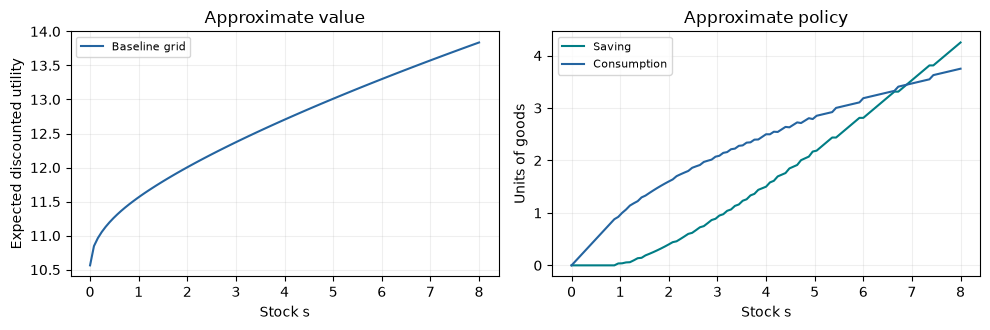

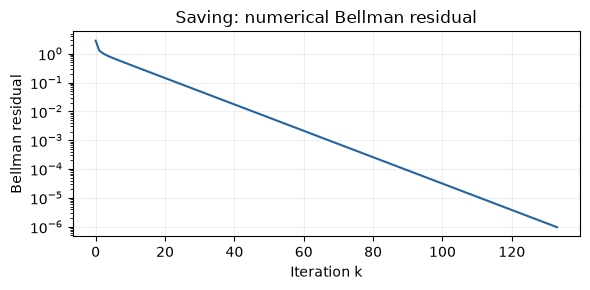

In [8]:
saving = ConsumptionSavingModel(M=5, B=3, alpha=0.5, beta=0.9)
saving_result = value_iteration(saving, tolerance=1e-5)
print("Completed updates:", saving_result["updates"])
print("Numerical-operator error bound:", saving_result["error_bound"])
plot_saving(saving, saving_result)
plot_convergence(saving_result, "Saving: numerical Bellman residual")
plt.show()

### Refine the numerical approximation

Double the stock and action intervals and use more income points. A small residual controls iteration error for the numerical operator; it does not remove grid and integration error.

Largest value difference on baseline points: 0.0026763881026781178


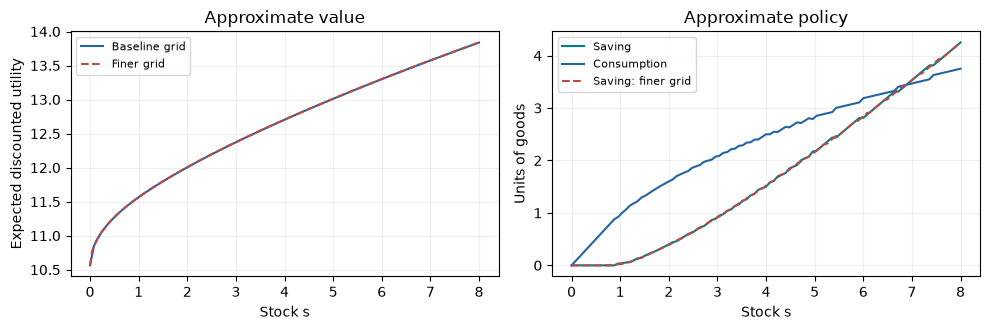

In [9]:
finer = ConsumptionSavingModel(n_states=201, n_actions=161, n_income=81)
finer_result = value_iteration(finer, tolerance=1e-5)
finer_values_at_old_points = np.interp(saving.states, finer.states, finer_result["values"])
print("Largest value difference on baseline points:",
      np.max(np.abs(saving_result["values"] - finer_values_at_old_points)))
plot_saving(saving, saving_result, finer, finer_result)
plt.show()

### Run a continuous-state simulation

Interpolate the computed saving choices to define an action at any stock. The income draws are real numbers, not the integration points used by the solver.

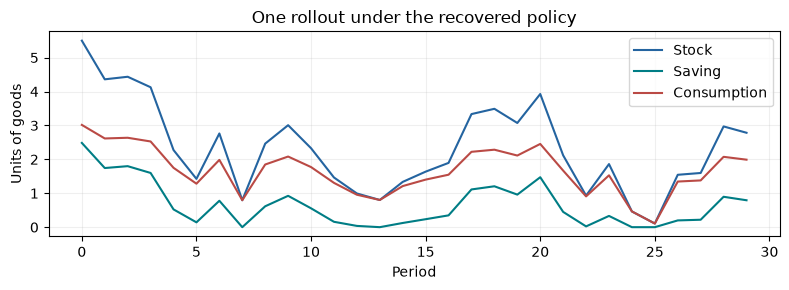

In [10]:
def saving_policy(stock):
    return np.interp(stock, saving.states, saving_result["policy"])

stocks, rewards = simulate_policy(saving, saving_policy, initial_state=5.5,
                                  periods=30, seed=7)
actions = np.array([saving_policy(s) for s in stocks[:-1]])
plot_saving_rollout(stocks, actions)
plt.show()

## References

1. **Richard S. Sutton and Andrew G. Barto (2018), *Reinforcement Learning: An Introduction*. 2nd ed. MIT Press.** [Chapter 3: Finite Markov Decision Processes](https://www.andrew.cmu.edu/course/10-703/textbook/BartoSutton.pdf#page=69); [Chapter 4: Dynamic Programming](https://www.andrew.cmu.edu/course/10-703/textbook/BartoSutton.pdf#page=95).
2. **Thomas J. Sargent and John Stachurski, QuantEcon.** [Discrete State Dynamic Programming: Value Function Iteration](https://tools-techniques.quantecon.org/discrete_dp.html#value-function-iteration); [Job Search I: The McCall Search Model](https://python.quantecon.org/mccall_model.html#the-mccall-model); [The Income Fluctuation Problem I: Basic Model](https://dynamics.quantecon.org/ifp.html#the-optimal-savings-problem).

The saving example uses the bounded-storage specification from Lab 2; the QuantEcon saving lecture provides related background.